In [19]:
from pathlib import Path
import pandas as pd
from IPython.display import display

# ===== Configuration =====
DATA_DIR = Path("data")
INPUT_FILENAME = "W03_Simulated_Dataset.csv"
PLATFORM = "Aido Rover"

RANDOM_STATE = 42
N_SCENARIOS = 250
PROJECT_YEARS = 3
DISCOUNT_RATE = 0.10

KPI_COLUMNS = [
    "uptime_pct",
    "incident_detection_pct",
    "energy_kwh_per_hour",
]

BLS_YEAR = 2025
BLS_OCC_CODE = "33-9032"

BLS_RAW_DIR = DATA_DIR / "bls"
BLS_LOOKUP_PATH = DATA_DIR / "W07_BLS_Security_Guard_Wages.csv"
CASH_FLOW_PATH = DATA_DIR / "W07_Cash_Flow_Projection.csv"

FINANCIAL_ASSUMPTIONS = {
    "robot_purchase_cost_usd": 30000,
    "setup_fixed_cost_usd": 5000,
    "setup_cost_per_robot_usd": 1000,
    "annual_maintenance_rate": 0.08,

    "electricity_price_usd_per_kwh": 0.15,
    "charging_efficiency": 0.90,
    "scheduled_hours_per_day": 12,
    "patrol_utilization": 0.75,

    "annual_hours_per_fte": 2080,
    "labor_cost_multiplier": 1.25,
    "eligible_labor_share": 0.40,
    "cash_realization_rate": 0.50,
    "patrol_area_capacity_ha_per_robot": 5,

    "annual_wage_growth": 0.00,
    "annual_cost_growth": 0.00,
    "terminal_value_per_robot_usd": 0,
}

# Assumed monthly software fees per robot.
SUBSCRIPTION_TIERS = {
    "Basic": 250,
    "Standard": 500,
    "Advanced": 750,
}

ASSUMPTIONS_PATH = DATA_DIR / "W07_Financial_Assumptions.csv"

# ===== Scenario generation settings =====
SCENARIO_RANGES = {
    "robot_units": (1, 8),          # Inclusive integer range
    "patrol_area_ha": (2.0, 40.0),
    "security_staff_fte": (2, 12),  # Inclusive integer range
}

DAYS_PER_YEAR = 365
MONTHS_PER_YEAR = 12
TEST_SIZE = 0.20

TARGET_COLUMN = f"npv_{PROJECT_YEARS}yr_usd"
SCENARIOS_PATH = DATA_DIR / "W07_Deployment_Scenarios.csv"

FEATURE_COLUMNS = [
    "robot_units",
    "patrol_area_ha",
    "security_staff_fte",
    "labor_cost_index",
    "uptime_rate",
    "incident_detection_rate",
    "annual_energy_cost_per_robot",
    "subscription_tier",
]

# ===== Load Week 3 data =====
input_path = DATA_DIR / INPUT_FILENAME

if not input_path.is_file():
    raise FileNotFoundError(
        f"Place {INPUT_FILENAME} in the data folder."
    )

week3_df = pd.read_csv(input_path)

required_columns = ["platform", "unit_id", "month"] + KPI_COLUMNS
missing_columns = set(required_columns) - set(week3_df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {sorted(missing_columns)}")

aido_df = week3_df.loc[
    week3_df["platform"].eq(PLATFORM)
].copy()

if aido_df.empty:
    raise ValueError(f"No records found for {PLATFORM}.")

print(f"Total Week 3 records: {len(week3_df)}")
print(f"{PLATFORM} records: {len(aido_df)}")
print(f"Deployment units: {aido_df['unit_id'].nunique()}")
print(f"Months: {aido_df['month'].nunique()}")

display(aido_df[required_columns].head())

print("\nKPI summary:")
display(aido_df[KPI_COLUMNS].describe().T.round(3))

print("\nMissing KPI values:")
display(aido_df[KPI_COLUMNS].isna().sum())

MONEY_ATOL_USD = 0.01

TRAIN_PATH = DATA_DIR / "W07_Train.csv"
TEST_PATH = DATA_DIR / "W07_Test.csv"

OUTPUT_DIR = Path("outputs")
NPV_HIST_BINS = 25
NPV_PLOT_PATH = OUTPUT_DIR / "W07_Training_NPV_Distribution.png"

# ===== Model comparison settings =====
CV_FOLDS = 5
CV_N_JOBS = 1

CATEGORICAL_FEATURES = ["subscription_tier"]

MODEL_PARAMS = {
    "Linear Regression": {
        "fit_intercept": True,
    },
    "Random Forest": {
        "n_estimators": 300,
        "max_depth": None,
        "min_samples_leaf": 2,
        "random_state": RANDOM_STATE,
        "n_jobs": 1,
    },
    "Gradient Boosting": {
        "n_estimators": 200,
        "learning_rate": 0.05,
        "max_depth": 2,
        "min_samples_leaf": 2,
        "random_state": RANDOM_STATE,
    },
}

CV_RESULTS_PATH = OUTPUT_DIR / "W07_CV_Model_Comparison.csv"
CV_FOLD_RESULTS_PATH = OUTPUT_DIR / "W07_CV_Fold_Results.csv"

TEST_METRICS_PATH = OUTPUT_DIR / "W07_Test_Metrics.csv"
TEST_PREDICTIONS_PATH = OUTPUT_DIR / "W07_Test_Predictions.csv"
SELECTED_MODEL_PATH = OUTPUT_DIR / "W07_Selected_Model.joblib"
TEST_PLOT_PATH = OUTPUT_DIR / "W07_Test_Prediction_Diagnostics.png"

IMPORTANCE_REFERENCE_MODEL = "Random Forest"
IMPORTANCE_RESULTS_PATH = OUTPUT_DIR / "W07_Feature_Importance.csv"
IMPORTANCE_PLOT_PATH = OUTPUT_DIR / "W07_Feature_Importance.png"

SENSITIVITY_BASE_POSITION = 0
SENSITIVITY_FEATURES = ["robot_units", "security_staff_fte"]
SENSITIVITY_RESULTS_PATH = OUTPUT_DIR / "W07_Sensitivity_Analysis.csv"
SENSITIVITY_PLOT_PATH = OUTPUT_DIR / "W07_Sensitivity_Analysis.png"

Total Week 3 records: 180
Aido Rover records: 60
Deployment units: 5
Months: 12


,platform,unit_id,month,uptime_pct,incident_detection_pct,energy_kwh_per_hour
0,Aido Rover,AR-01,2025-01-01,96.187708,82.417582,0.223018
1,Aido Rover,AR-02,2025-01-01,94.134543,85.074627,0.197169
2,Aido Rover,AR-03,2025-01-01,94.326833,93.684211,0.128541
3,Aido Rover,AR-04,2025-01-01,99.894718,98.666667,0.224020
4,Aido Rover,AR-05,2025-01-01,96.316179,86.419753,0.240853



KPI summary:


,count,mean,std,min,25%,50%,75%,max
uptime_pct,60.0,96.982,1.618,94.135,95.721,97.276,98.250,99.895
incident_detection_pct,60.0,93.079,4.147,82.418,90.513,92.913,96.552,100.000
energy_kwh_per_hour,60.0,0.197,0.046,0.121,0.164,0.198,0.229,0.274



Missing KPI values:


uptime_pct                0
incident_detection_pct    0
energy_kwh_per_hour       0
dtype: int64

## Deployment Scenario and Prediction Target

This project estimates the three-year deployment NPV of Aido Rover
using public cost proxies and clearly documented synthetic scenarios.

Each row represents one deployment scenario. The planned dataset
contains 250 scenarios, generated with random_state = 42.

### Input Variables

| Variable | Definition | Unit | Planned Source |
|---|---|---|---|
| robot_units | Number of robots deployed | Count | Simulation assumption |
| patrol_area_ha | Total designated patrol area | Hectares | Simulation assumption |
| security_staff_fte | Existing full-time-equivalent security staff | FTE | Simulation assumption |
| labor_cost_index | Regional security guard wage divided by the national wage | Ratio | BLS wage data |
| uptime_rate | Operational availability | 0–1 | Week 3 synthetic uptime_pct / 100 |
| incident_detection_rate | Proportion of verified incidents detected | 0–1 | Week 3 synthetic incident_detection_pct / 100 |
| annual_energy_cost_per_robot | Estimated annual electricity cost per robot | USD/year | Week 3 energy intensity and documented operating assumptions |
| subscription_tier | Software or service subscription level | Category | Assumed tiers informed by public comparable pricing |

### Financial Calculation

The prediction target is three-year NPV in USD:

NPV = -Initial Investment
      + Net Cash Flow Year 1 / (1.10)
      + Net Cash Flow Year 2 / (1.10 ** 2)
      + Net Cash Flow Year 3 / (1.10 ** 3)

Annual net cash flow includes:
- Realizable labor cost savings.
- Robot operating, subscription, maintenance, and electricity costs.

Initial investment includes applicable hardware and implementation costs.

### Modeling Boundaries

- The 10% discount rate follows the plan.
- Labor savings require an explicit assumption about hours actually reduced.
- Incident detection is not converted into avoided financial losses without
  a documented valuation assumption.
- Bundled subscription costs must not duplicate hardware or maintenance costs.
- Synthetic scenarios do not represent actual InGen deployment results.
- Model evaluation measures performance within the simulated scenarios.

In [2]:
from io import BytesIO
from zipfile import ZipFile
from urllib.request import Request, urlopen

BLS_RAW_DIR.mkdir(parents=True, exist_ok=True)


def load_bls_wages(kind):
    filename = f"oesm{BLS_YEAR % 100:02d}{kind}.zip"
    url = f"https://www.bls.gov/oes/special-requests/{filename}"
    local_path = BLS_RAW_DIR / filename

    if not local_path.exists():
        print(f"Downloading {filename}...")

        request = Request(
            url,
            headers={"User-Agent": "Mozilla/5.0"}
        )

        with urlopen(request, timeout=30) as response:
            content = response.read()

        # Check the download before caching it.
        with ZipFile(BytesIO(content)):
            pass

        local_path.write_bytes(content)

    with ZipFile(local_path) as archive:
        excel_file = next(
            name for name in archive.namelist()
            if name.endswith(".xlsx")
        )
        raw = pd.read_excel(
            BytesIO(archive.read(excel_file))
        )

    # Security Guards, all industries, combined ownership.
    selected = (
        raw["OCC_CODE"].eq(BLS_OCC_CODE)
        & pd.to_numeric(raw["NAICS"], errors="coerce").eq(0)
        & raw["OWN_CODE"].eq(1235)
    )

    return raw.loc[selected].copy(), url


national_df, national_url = load_bls_wages("nat")
state_df, state_url = load_bls_wages("st")

national_row = national_df.loc[
    national_df["AREA_TYPE"].eq(1)
]

assert len(national_row) == 1, "Expected one national wage record."

national_annual_wage = float(
    national_row["A_MEAN"].iloc[0]
)

# AREA_TYPE = 2 includes the 50 states and Washington, DC.
wage_reference = state_df.loc[
    state_df["AREA_TYPE"].eq(2),
    ["AREA_TITLE", "PRIM_STATE", "H_MEAN", "A_MEAN"]
].copy()

wage_reference.columns = [
    "region",
    "state_code",
    "hourly_wage_usd",
    "annual_wage_usd"
]

for column in ["hourly_wage_usd", "annual_wage_usd"]:
    wage_reference[column] = pd.to_numeric(
        wage_reference[column],
        errors="raise"
    )

assert national_annual_wage > 0
assert len(wage_reference) == 51
assert wage_reference["state_code"].is_unique
assert wage_reference[
    ["hourly_wage_usd", "annual_wage_usd"]
].gt(0).all().all()

wage_reference["national_annual_wage_usd"] = national_annual_wage
wage_reference["labor_cost_index"] = (
    wage_reference["annual_wage_usd"]
    / national_annual_wage
)

# Retain source information with the prepared data.
wage_reference["source_period"] = f"May {BLS_YEAR}"
wage_reference["occupation_code"] = BLS_OCC_CODE
wage_reference["wage_statistic"] = "mean"
wage_reference["state_source_url"] = state_url
wage_reference["national_source_url"] = national_url
wage_reference["data_origin"] = "PUBLIC_BLS"

wage_reference = (
    wage_reference
    .sort_values("state_code")
    .reset_index(drop=True)
)

wage_reference.to_csv(
    BLS_LOOKUP_PATH,
    index=False,
    encoding="utf-8-sig"
)

print(f"\nNational mean annual wage: ${national_annual_wage:,.0f}")
print(f"State/DC records: {len(wage_reference)}")
print(f"Saved: {BLS_LOOKUP_PATH}")

display(
    wage_reference[
        ["region", "annual_wage_usd", "labor_cost_index"]
    ].round(3)
)


National mean annual wage: $42,470
State/DC records: 51
Saved: data\W07_BLS_Security_Guard_Wages.csv


,region,annual_wage_usd,labor_cost_index
0,Alaska,54140,1.275
1,Alabama,34680,0.817
2,Arkansas,38300,0.902
3,Arizona,40950,0.964
4,California,44920,1.058
5,Colorado,45870,1.080
6,Connecticut,45180,1.064
7,District of Columbia,60720,1.430
8,Delaware,43750,1.030
9,Florida,37610,0.886


In [3]:
assumption_rows = [
    {
        "parameter": parameter,
        "value": value,
        "source_type": "ANALYST_ASSUMPTION",
    }
    for parameter, value in FINANCIAL_ASSUMPTIONS.items()
]

assumption_rows.extend(
    {
        "parameter": f"monthly_software_fee_usd_{tier.lower()}",
        "value": monthly_fee,
        "source_type": "ANALYST_ASSUMPTION",
    }
    for tier, monthly_fee in SUBSCRIPTION_TIERS.items()
)

assumptions_df = pd.DataFrame(assumption_rows)

assumptions_df.to_csv(
    ASSUMPTIONS_PATH,
    index=False,
    encoding="utf-8-sig"
)

display(assumptions_df)
print(f"Saved: {ASSUMPTIONS_PATH}")

,parameter,value,source_type
0,robot_purchase_cost_usd,30000.00,ANALYST_ASSUMPTION
1,setup_fixed_cost_usd,5000.00,ANALYST_ASSUMPTION
2,setup_cost_per_robot_usd,1000.00,ANALYST_ASSUMPTION
3,annual_maintenance_rate,0.08,ANALYST_ASSUMPTION
4,electricity_price_usd_per_kwh,0.15,ANALYST_ASSUMPTION
5,charging_efficiency,0.90,ANALYST_ASSUMPTION
6,scheduled_hours_per_day,12.00,ANALYST_ASSUMPTION
7,patrol_utilization,0.75,ANALYST_ASSUMPTION
8,annual_hours_per_fte,2080.00,ANALYST_ASSUMPTION
9,labor_cost_multiplier,1.25,ANALYST_ASSUMPTION


Saved: data\W07_Financial_Assumptions.csv


In [5]:
import numpy as np

# Reset the generator so rerunning this cell reproduces the scenarios.
rng = np.random.default_rng(RANDOM_STATE)

# Stable reference ordering.
operating_reference = (
    aido_df
    .sort_values(["unit_id", "month"])
    .reset_index(drop=True)
)

wage_pool = (
    wage_reference
    .sort_values("state_code")
    .reset_index(drop=True)
)

# Sample complete operational rows to preserve KPI relationships.
operating_sample = operating_reference.iloc[
    rng.integers(0, len(operating_reference), size=N_SCENARIOS)
].reset_index(drop=True)

# Give each state/DC equal sampling probability.
wage_sample = wage_pool.iloc[
    rng.integers(0, len(wage_pool), size=N_SCENARIOS)
].reset_index(drop=True)

robot_min, robot_max = SCENARIO_RANGES["robot_units"]
area_min, area_max = SCENARIO_RANGES["patrol_area_ha"]
staff_min, staff_max = SCENARIO_RANGES["security_staff_fte"]

scenario_df = pd.DataFrame({
    "scenario_id": [
        f"SCN_{i:04d}" for i in range(1, N_SCENARIOS + 1)
    ],
    "platform": PLATFORM,
    "robot_units": rng.integers(
        robot_min, robot_max + 1, size=N_SCENARIOS
    ),
    "patrol_area_ha": rng.uniform(
        area_min, area_max, size=N_SCENARIOS
    ).round(2),
    "security_staff_fte": rng.integers(
        staff_min, staff_max + 1, size=N_SCENARIOS
    ),
    "state_code": wage_sample["state_code"],
    "region": wage_sample["region"],
    "annual_wage_usd": wage_sample["annual_wage_usd"],
    "labor_cost_index": wage_sample["labor_cost_index"],
    "uptime_rate": operating_sample["uptime_pct"] / 100,
    "incident_detection_rate": (
        operating_sample["incident_detection_pct"] / 100
    ),
    "energy_kwh_per_hour": operating_sample["energy_kwh_per_hour"],
    "subscription_tier": rng.choice(
        list(SUBSCRIPTION_TIERS), size=N_SCENARIOS
    ),
    "operating_reference_unit": operating_sample["unit_id"],
    "operating_reference_month": operating_sample["month"],
    "data_origin": "SYNTHETIC_SCENARIO",
})

# Estimate electricity cost from active patrol energy use.
assumptions = FINANCIAL_ASSUMPTIONS

assert 0 < assumptions["charging_efficiency"] <= 1

annual_active_hours_per_robot = (
    DAYS_PER_YEAR
    * assumptions["scheduled_hours_per_day"]
    * scenario_df["uptime_rate"]
    * assumptions["patrol_utilization"]
)

scenario_df["annual_energy_cost_per_robot"] = (
    annual_active_hours_per_robot
    * scenario_df["energy_kwh_per_hour"]
    / assumptions["charging_efficiency"]
    * assumptions["electricity_price_usd_per_kwh"]
)

scenario_df["monthly_software_fee_usd"] = (
    scenario_df["subscription_tier"].map(SUBSCRIPTION_TIERS)
)

# Validate the generated inputs.
assert len(scenario_df) == N_SCENARIOS
assert scenario_df["scenario_id"].is_unique
assert scenario_df[FEATURE_COLUMNS].notna().all().all()
assert np.isfinite(
    scenario_df.select_dtypes(include="number").to_numpy()
).all()

for column in ["uptime_rate", "incident_detection_rate"]:
    assert scenario_df[column].between(0, 1).all()

print(f"Scenario inputs generated: {len(scenario_df)}")
print(f"Model input features: {len(FEATURE_COLUMNS)}")
print(
    "Missing predictor values:",
    scenario_df[FEATURE_COLUMNS].isna().sum().sum()
)

display(
    scenario_df[["scenario_id"] + FEATURE_COLUMNS]
    .head()
    .round(4)
)

Scenario inputs generated: 250
Model input features: 8
Missing predictor values: 0


,scenario_id,robot_units,patrol_area_ha,security_staff_fte,labor_cost_index,uptime_rate,incident_detection_rate,annual_energy_cost_per_robot,subscription_tier
0,SCN_0001,1,7.62,4,0.8856,0.9794,0.9643,112.8454,Standard
1,SCN_0002,6,37.57,6,0.7476,0.9585,1.0000,64.2076,Basic
2,SCN_0003,8,18.64,2,0.8856,0.9698,1.0000,117.2342,Basic
3,SCN_0004,7,16.57,10,0.9501,0.9431,0.9231,70.1474,Basic
4,SCN_0005,3,29.73,9,0.9364,0.9540,0.9390,110.4122,Standard


In [7]:
def calculate_deployment_npv(
    scenarios,
    assumptions,
    tiers,
    project_years,
    discount_rate,
    days_per_year,
    months_per_year,
):
    d = scenarios.copy().reset_index(drop=True)
    a = assumptions

    assert project_years >= 1 and int(project_years) == project_years
    assert discount_rate > -1

    for key in [
        "eligible_labor_share",
        "cash_realization_rate",
        "patrol_utilization",
    ]:
        assert 0 <= a[key] <= 1

    # 1. Estimate the share of the patrol area covered.
    d["area_coverage_fraction"] = np.minimum(
        1.0,
        d["robot_units"]
        * a["patrol_area_capacity_ha_per_robot"]
        / d["patrol_area_ha"],
    )

    # 2. Cap potential labor savings by eligible work and robot hours.
    eligible_hours = (
        d["security_staff_fte"]
        * a["annual_hours_per_fte"]
        * a["eligible_labor_share"]
        * d["area_coverage_fraction"]
        * d["uptime_rate"]
    )

    available_hours = (
        d["robot_units"]
        * days_per_year
        * a["scheduled_hours_per_day"]
        * a["patrol_utilization"]
        * d["uptime_rate"]
    )

    d["potential_labor_hours_saved"] = np.minimum(
        eligible_hours, available_hours
    )

    d["realized_labor_hours_saved"] = (
        d["potential_labor_hours_saved"]
        * a["cash_realization_rate"]
    )

    d["realized_fte_saved"] = (
        d["realized_labor_hours_saved"]
        / a["annual_hours_per_fte"]
    )

    d["annual_labor_savings_usd"] = (
        d["realized_fte_saved"]
        * d["annual_wage_usd"]
        * a["labor_cost_multiplier"]
    )

    # 3. Calculate first-year operating costs.
    d["monthly_software_fee_usd"] = (
        d["subscription_tier"].map(tiers)
    )
    assert d["monthly_software_fee_usd"].notna().all()

    d["annual_maintenance_cost_usd"] = (
        d["robot_units"]
        * a["robot_purchase_cost_usd"]
        * a["annual_maintenance_rate"]
    )

    d["annual_software_cost_usd"] = (
        d["robot_units"]
        * d["monthly_software_fee_usd"]
        * months_per_year
    )

    d["annual_energy_cost_usd"] = (
        d["robot_units"]
        * d["annual_energy_cost_per_robot"]
    )

    d["annual_operating_cost_usd"] = (
        d["annual_maintenance_cost_usd"]
        + d["annual_software_cost_usd"]
        + d["annual_energy_cost_usd"]
    )

    # 4. Record hardware and implementation costs at Year 0.
    d["initial_investment_usd"] = (
        d["robot_units"]
        * (
            a["robot_purchase_cost_usd"]
            + a["setup_cost_per_robot_usd"]
        )
        + a["setup_fixed_cost_usd"]
    )

    frames = [
        pd.DataFrame({
            "scenario_id": d["scenario_id"],
            "year": 0,
            "labor_savings_usd": 0.0,
            "operating_cost_usd": 0.0,
            "terminal_value_usd": 0.0,
            "initial_investment_usd": d["initial_investment_usd"],
            "net_cash_flow_usd": -d["initial_investment_usd"],
        })
    ]

    # 5. Project annual cash flows.
    for year in range(1, project_years + 1):
        savings = (
            d["annual_labor_savings_usd"]
            * (1 + a["annual_wage_growth"]) ** (year - 1)
        )

        costs = (
            d["annual_operating_cost_usd"]
            * (1 + a["annual_cost_growth"]) ** (year - 1)
        )

        terminal = (
            d["robot_units"] * a["terminal_value_per_robot_usd"]
            if year == project_years
            else 0.0
        )

        frames.append(
            pd.DataFrame({
                "scenario_id": d["scenario_id"],
                "year": year,
                "labor_savings_usd": savings,
                "operating_cost_usd": costs,
                "terminal_value_usd": terminal,
                "initial_investment_usd": 0.0,
                "net_cash_flow_usd": savings - costs + terminal,
            })
        )

    cash_flows = pd.concat(frames, ignore_index=True)

    # Year 0 has a discount factor of 1.
    cash_flows["discounted_cash_flow_usd"] = (
        cash_flows["net_cash_flow_usd"]
        / (1 + discount_rate) ** cash_flows["year"]
    )

    target = f"npv_{project_years}yr_usd"

    d[target] = d["scenario_id"].map(
        cash_flows.groupby("scenario_id")[
            "discounted_cash_flow_usd"
        ].sum()
    )

    cash_flows = (
        cash_flows
        .sort_values(["scenario_id", "year"])
        .reset_index(drop=True)
    )

    return d, cash_flows


deployment_df, cashflow_df = calculate_deployment_npv(
    scenarios=scenario_df,
    assumptions=FINANCIAL_ASSUMPTIONS,
    tiers=SUBSCRIPTION_TIERS,
    project_years=PROJECT_YEARS,
    discount_rate=DISCOUNT_RATE,
    days_per_year=DAYS_PER_YEAR,
    months_per_year=MONTHS_PER_YEAR,
)

deployment_df.to_csv(
    SCENARIOS_PATH, index=False, encoding="utf-8-sig"
)

cashflow_df.to_csv(
    CASH_FLOW_PATH, index=False, encoding="utf-8-sig"
)

print(f"Deployment scenarios: {len(deployment_df)}")
print(f"Cash-flow records: {len(cashflow_df)}")
print(f"Target column: {TARGET_COLUMN}")

display(
    deployment_df[[
        "scenario_id",
        "initial_investment_usd",
        "realized_fte_saved",
        "annual_labor_savings_usd",
        "annual_operating_cost_usd",
        TARGET_COLUMN,
    ]].head().round(2)
)

Deployment scenarios: 250
Cash-flow records: 1000
Target column: npv_3yr_usd


,scenario_id,initial_investment_usd,realized_fte_saved,annual_labor_savings_usd,annual_operating_cost_usd,npv_3yr_usd
0,SCN_0001,36000,0.51,24170.98,8512.85,2939.47
1,SCN_0002,191000,0.92,36451.56,32785.25,-181882.42
2,SCN_0003,253000,0.39,18236.47,44137.87,-317412.95
3,SCN_0004,222000,1.89,95131.76,38291.03,-80645.53
4,SCN_0005,98000,0.87,43069.34,25531.24,-54385.33


In [9]:
from sklearn.model_selection import train_test_split

# ===== Data quality checks =====
assert len(deployment_df) == N_SCENARIOS
assert deployment_df["scenario_id"].is_unique

assert deployment_df[
    FEATURE_COLUMNS + [TARGET_COLUMN]
].notna().all().all()

assert np.isfinite(
    deployment_df.select_dtypes(include="number").to_numpy()
).all()

assert set(cashflow_df["scenario_id"]) == set(
    deployment_df["scenario_id"]
)

assert not cashflow_df.duplicated(
    ["scenario_id", "year"]
).any()

assert set(cashflow_df["year"]) == set(
    range(PROJECT_YEARS + 1)
)

assert cashflow_df.groupby("scenario_id").size().eq(
    PROJECT_YEARS + 1
).all()

# Realized labor savings must remain within the configured limit.
maximum_realized_fte = (
    deployment_df["security_staff_fte"]
    * FINANCIAL_ASSUMPTIONS["eligible_labor_share"]
    * FINANCIAL_ASSUMPTIONS["cash_realization_rate"]
)

assert deployment_df["realized_fte_saved"].ge(0).all()
assert (
    deployment_df["realized_fte_saved"]
    <= maximum_realized_fte + 1e-8
).all()

# ===== Independent NPV reconciliation =====
years = np.arange(1, PROJECT_YEARS + 1)

savings_pv_factor = np.sum(
    (1 + FINANCIAL_ASSUMPTIONS["annual_wage_growth"]) ** (years - 1)
    / (1 + DISCOUNT_RATE) ** years
)

cost_pv_factor = np.sum(
    (1 + FINANCIAL_ASSUMPTIONS["annual_cost_growth"]) ** (years - 1)
    / (1 + DISCOUNT_RATE) ** years
)

expected_npv = (
    -deployment_df["initial_investment_usd"]
    + deployment_df["annual_labor_savings_usd"] * savings_pv_factor
    - deployment_df["annual_operating_cost_usd"] * cost_pv_factor
    + (
        deployment_df["robot_units"]
        * FINANCIAL_ASSUMPTIONS["terminal_value_per_robot_usd"]
        / (1 + DISCOUNT_RATE) ** PROJECT_YEARS
    )
)

assert np.allclose(
    deployment_df[TARGET_COLUMN],
    expected_npv,
    rtol=0,
    atol=MONEY_ATOL_USD,
), "NPV reconciliation failed."

# ===== Freeze the train/test split =====
model_df = deployment_df[
    ["scenario_id"] + FEATURE_COLUMNS + [TARGET_COLUMN]
].copy()

train_df, test_df = train_test_split(
    model_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
)

assert set(train_df["scenario_id"]).isdisjoint(
    set(test_df["scenario_id"])
)

train_df.to_csv(TRAIN_PATH, index=False, encoding="utf-8-sig")
test_df.to_csv(TEST_PATH, index=False, encoding="utf-8-sig")

print("Data quality and financial validation passed.")
print(f"Training records: {len(train_df)}")
print(f"Test records: {len(test_df)}")
print(f"Predictor count: {len(FEATURE_COLUMNS)}")

Data quality and financial validation passed.
Training records: 200
Test records: 50
Predictor count: 8


,Training NPV (USD)
count,200.00
mean,-107899.62
std,118530.89
min,-429373.92
25%,-191226.36
50%,-80974.66
75%,-29270.81
max,195862.52


Positive NPV share in training set: 17.0%


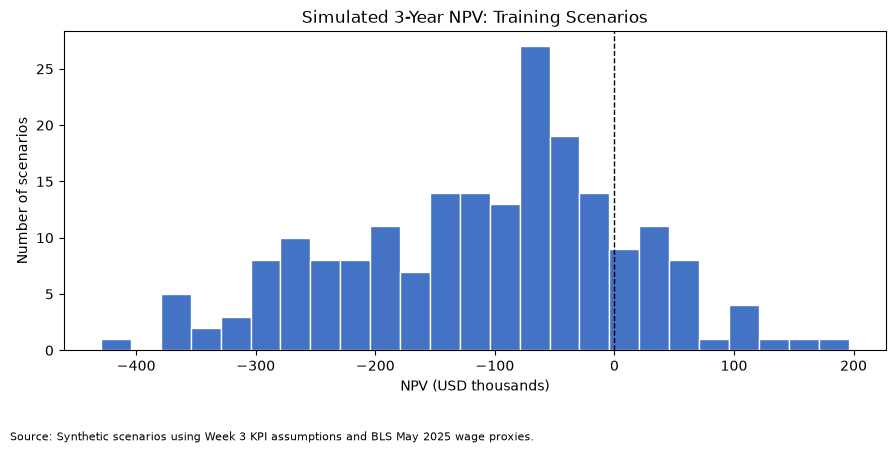

In [10]:
import matplotlib.pyplot as plt

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

display(
    train_df[TARGET_COLUMN]
    .describe()
    .round(2)
    .to_frame("Training NPV (USD)")
)

positive_share = train_df[TARGET_COLUMN].gt(0).mean()
print(f"Positive NPV share in training set: {positive_share:.1%}")

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(
    train_df[TARGET_COLUMN] / 1000,
    bins=NPV_HIST_BINS,
    color="#4472C4",
    edgecolor="white",
)

ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_title(f"Simulated {PROJECT_YEARS}-Year NPV: Training Scenarios")
ax.set_xlabel("NPV (USD thousands)")
ax.set_ylabel("Number of scenarios")

fig.text(
    0.01, 0.01,
    f"Source: Synthetic scenarios using Week 3 KPI assumptions "
    f"and BLS May {BLS_YEAR} wage proxies.",
    fontsize=8,
)

fig.tight_layout(rect=[0, 0.08, 1, 1])
fig.savefig(NPV_PLOT_PATH, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

In [12]:
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.model_selection import KFold, cross_validate

# ===== Load the frozen training data =====
training_data = pd.read_csv(TRAIN_PATH)

X_train = training_data[FEATURE_COLUMNS].copy()
y_train = training_data[TARGET_COLUMN].copy()

numeric_features = [
    column for column in FEATURE_COLUMNS
    if column not in CATEGORICAL_FEATURES
]

print(f"scikit-learn version: {sklearn.__version__}")
print(f"Training input shape: {X_train.shape}")
print(f"Numeric features: {len(numeric_features)}")
print(f"Categorical features: {len(CATEGORICAL_FEATURES)}")

# ===== Preprocessing fitted within each CV training fold =====
preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            StandardScaler(),
            numeric_features,
        ),
        (
            "categorical",
            OneHotEncoder(
                categories=[list(SUBSCRIPTION_TIERS)],
                drop="first",
                handle_unknown="ignore",
            ),
            CATEGORICAL_FEATURES,
        ),
    ],
    sparse_threshold=0,
)

estimators = {
    "Linear Regression": LinearRegression(
        **MODEL_PARAMS["Linear Regression"]
    ),
    "Random Forest": RandomForestRegressor(
        **MODEL_PARAMS["Random Forest"]
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        **MODEL_PARAMS["Gradient Boosting"]
    ),
}

model_pipelines = {
    name: Pipeline([
        ("preprocess", clone(preprocessor)),
        ("model", estimator),
    ])
    for name, estimator in estimators.items()
}

# Reuse identical folds for every model.
cv_splits = list(
    KFold(
        n_splits=CV_FOLDS,
        shuffle=True,
        random_state=RANDOM_STATE,
    ).split(X_train, y_train)
)

comparison_rows = []
fold_rows = []

for name, pipeline in model_pipelines.items():
    print(f"\nEvaluating: {name}")

    scores = cross_validate(
        estimator=pipeline,
        X=X_train,
        y=y_train,
        cv=cv_splits,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        return_train_score=True,
        n_jobs=CV_N_JOBS,
        error_score="raise",
    )

    # Convert sklearn's negative RMSE scores into positive USD errors.
    validation_rmse = -scores["test_rmse"]
    training_rmse = -scores["train_rmse"]

    comparison_rows.append({
        "model": name,
        "cv_rmse_mean_usd": validation_rmse.mean(),
        "cv_rmse_sd_usd": validation_rmse.std(ddof=1),
        "cv_r2_mean": scores["test_r2"].mean(),
        "cv_train_rmse_mean_usd": training_rmse.mean(),
    })

    for fold in range(CV_FOLDS):
        fold_rows.append({
            "model": name,
            "fold": fold + 1,
            "training_rmse_usd": training_rmse[fold],
            "validation_rmse_usd": validation_rmse[fold],
            "validation_r2": scores["test_r2"][fold],
        })

cv_results_df = (
    pd.DataFrame(comparison_rows)
    .sort_values("cv_rmse_mean_usd")
    .reset_index(drop=True)
)

cv_fold_results_df = pd.DataFrame(fold_rows)

# Select using training-set cross-validation.
selected_model_name = cv_results_df.loc[0, "model"]
selected_pipeline = clone(
    model_pipelines[selected_model_name]
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cv_results_df.to_csv(
    CV_RESULTS_PATH, index=False, encoding="utf-8-sig"
)

cv_fold_results_df.to_csv(
    CV_FOLD_RESULTS_PATH, index=False, encoding="utf-8-sig"
)

display(
    cv_results_df.round({
        "cv_rmse_mean_usd": 2,
        "cv_rmse_sd_usd": 2,
        "cv_r2_mean": 4,
        "cv_train_rmse_mean_usd": 2,
    })
)

print(f"\nSelected model by CV RMSE: {selected_model_name}")

scikit-learn version: 1.9.1
Training input shape: (200, 8)
Numeric features: 7
Categorical features: 1

Evaluating: Linear Regression

Evaluating: Random Forest

Evaluating: Gradient Boosting


,model,cv_rmse_mean_usd,cv_rmse_sd_usd,cv_r2_mean,cv_train_rmse_mean_usd
0,Gradient Boosting,28357.41,3295.55,0.9403,14425.21
1,Linear Regression,39568.64,4515.62,0.8843,36098.14
2,Random Forest,41057.68,4075.67,0.8768,20189.72



Selected model by CV RMSE: Gradient Boosting


In [14]:
import numpy as np
import joblib
from sklearn.metrics import mean_squared_error, r2_score

# Load the held-out test set.
test_data = pd.read_csv(TEST_PATH)
X_test = test_data[FEATURE_COLUMNS].copy()
y_test = test_data[TARGET_COLUMN].copy()

assert set(training_data["scenario_id"]).isdisjoint(
    set(test_data["scenario_id"])
), "Training and test scenarios must not overlap."

# Fit the CV-selected pipeline on all training records.
selected_pipeline.fit(X_train, y_train)

# Evaluate the selected model on the held-out test set.
test_predictions = selected_pipeline.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
test_r2 = r2_score(y_test, test_predictions)

selected_cv = cv_results_df.loc[
    cv_results_df["model"] == selected_model_name
].iloc[0]

test_metrics_df = pd.DataFrame([{
    "model": selected_model_name,
    "training_records": len(X_train),
    "test_records": len(X_test),
    "cv_rmse_mean_usd": selected_cv["cv_rmse_mean_usd"],
    "cv_r2_mean": selected_cv["cv_r2_mean"],
    "test_rmse_usd": test_rmse,
    "test_r2": test_r2,
}])

# Keep scenario IDs aligned with predictions.
test_predictions_df = pd.DataFrame({
    "scenario_id": test_data["scenario_id"].to_numpy(),
    "actual_npv_usd": y_test.to_numpy(),
    "predicted_npv_usd": test_predictions,
})

test_predictions_df["residual_usd"] = (
    test_predictions_df["actual_npv_usd"]
    - test_predictions_df["predicted_npv_usd"]
)
test_predictions_df["absolute_error_usd"] = (
    test_predictions_df["residual_usd"].abs()
)

# Export results and the complete fitted pipeline.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

test_metrics_df.to_csv(TEST_METRICS_PATH, index=False)
test_predictions_df.to_csv(TEST_PREDICTIONS_PATH, index=False)
joblib.dump(selected_pipeline, SELECTED_MODEL_PATH)

display(test_metrics_df.round(4))
display(test_predictions_df.head().round(2))

print("Test evaluation completed.")
print(f"Saved metrics: {TEST_METRICS_PATH}")
print(f"Saved predictions: {TEST_PREDICTIONS_PATH}")
print(f"Saved pipeline: {SELECTED_MODEL_PATH}")

,model,training_records,test_records,cv_rmse_mean_usd,cv_r2_mean,test_rmse_usd,test_r2
0,Gradient Boosting,200,50,28357.4149,0.9403,24205.1266,0.9589


,scenario_id,actual_npv_usd,predicted_npv_usd,residual_usd,absolute_error_usd
0,SCN_0143,-105953.28,-66907.94,-39045.35,39045.35
1,SCN_0007,-227868.37,-215163.81,-12704.55,12704.55
2,SCN_0098,-145200.04,-130357.71,-14842.33,14842.33
3,SCN_0061,-57951.90,-74718.58,16766.67,16766.67
4,SCN_0113,-292234.63,-278436.28,-13798.35,13798.35


Test evaluation completed.
Saved metrics: outputs\W07_Test_Metrics.csv
Saved predictions: outputs\W07_Test_Predictions.csv
Saved pipeline: outputs\W07_Selected_Model.joblib


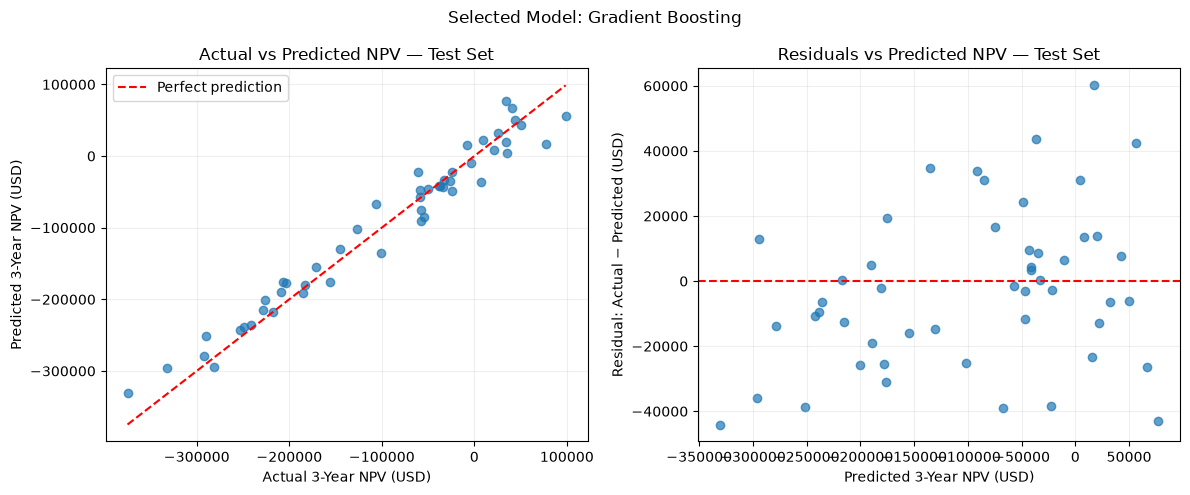

Test RMSE: $24,205.13
Test R²: 0.9589
Saved figure: outputs\W07_Test_Prediction_Diagnostics.png


In [16]:
import matplotlib.pyplot as plt

actual = test_predictions_df["actual_npv_usd"].to_numpy()
predicted = test_predictions_df["predicted_npv_usd"].to_numpy()
residuals = test_predictions_df["residual_usd"].to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare predictions with the calculated NPV targets.
lower = min(actual.min(), predicted.min())
upper = max(actual.max(), predicted.max())

axes[0].scatter(actual, predicted, alpha=0.7)
axes[0].plot(
    [lower, upper], [lower, upper],
    color="red", linestyle="--", label="Perfect prediction"
)
axes[0].set(
    title="Actual vs Predicted NPV — Test Set",
    xlabel="Actual 3-Year NPV (USD)",
    ylabel="Predicted 3-Year NPV (USD)"
)
axes[0].legend()

# Check whether prediction errors show a systematic pattern.
axes[1].scatter(predicted, residuals, alpha=0.7)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set(
    title="Residuals vs Predicted NPV — Test Set",
    xlabel="Predicted 3-Year NPV (USD)",
    ylabel="Residual: Actual − Predicted (USD)"
)

for ax in axes:
    ax.grid(alpha=0.2)
    ax.ticklabel_format(style="plain", axis="both")

fig.suptitle(f"Selected Model: {selected_model_name}")
fig.tight_layout()
fig.savefig(TEST_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Test RMSE: ${test_rmse:,.2f}")
print(f"Test R²: {test_r2:.4f}")
print(f"Saved figure: {TEST_PLOT_PATH}")

### Model Evaluation Summary

Gradient Boosting achieved the lowest mean RMSE in five-fold
cross-validation and was selected for final evaluation.

After fitting the pipeline on 200 training scenarios, the model
achieved a test RMSE of $24,205.13 and an R² of 0.9589 on 50
held-out scenarios. Most predictions were close to the calculated
NPV targets, although several scenarios had substantial residuals.

These results demonstrate strong predictive performance within
the simulated scenario distribution. Because the NPV targets were
generated using predefined financial assumptions, this evaluation
does not establish accuracy for real-world deployment returns.

model,Gradient Boosting,Random Forest
feature,,
robot_units,46.94,47.15
security_staff_fte,34.32,33.55
subscription_tier,7.48,4.01
patrol_area_ha,5.80,8.00
labor_cost_index,5.05,3.63
incident_detection_rate,0.24,1.08
annual_energy_cost_per_robot,0.13,1.21
uptime_rate,0.04,1.36


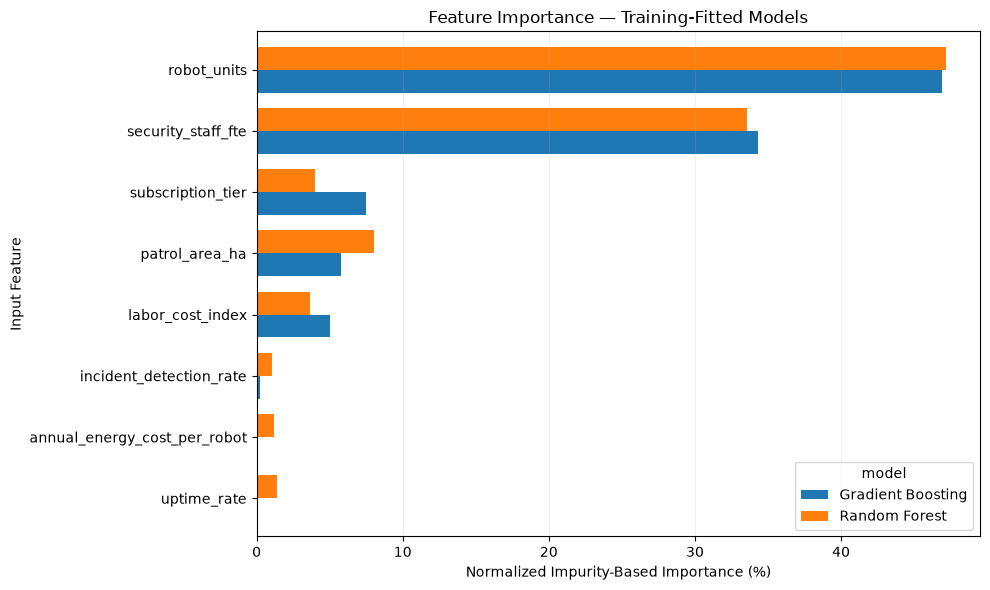

Saved importance table: outputs\W07_Feature_Importance.csv
Saved importance figure: outputs\W07_Feature_Importance.png


In [18]:
from sklearn.base import clone
import matplotlib.pyplot as plt

# Fit the reference model using training data only.
reference_pipeline = clone(
    model_pipelines[IMPORTANCE_REFERENCE_MODEL]
)
reference_pipeline.fit(X_train, y_train)

importance_pipelines = {
    selected_model_name: selected_pipeline,
    IMPORTANCE_REFERENCE_MODEL: reference_pipeline,
}

importance_tables = []

for model_name, pipeline in importance_pipelines.items():
    feature_names = (
        pipeline.named_steps["preprocess"].get_feature_names_out()
    )
    importance_values = (
        pipeline.named_steps["model"].feature_importances_
    )

    # Map encoded columns back to the original input features.
    original_features = []

    for encoded_name in feature_names:
        feature = encoded_name.split("__", 1)[-1]

        for categorical_feature in CATEGORICAL_FEATURES:
            if feature.startswith(f"{categorical_feature}_"):
                feature = categorical_feature
                break

        original_features.append(feature)

    encoded_importance = pd.DataFrame({
        "feature": original_features,
        "importance": importance_values,
    })

    # Combine subscription-tier dummy variables into one feature.
    grouped_importance = (
        encoded_importance.groupby("feature")["importance"]
        .sum()
        .reindex(FEATURE_COLUMNS, fill_value=0)
        .rename_axis("feature")
        .reset_index()
    )

    grouped_importance["model"] = model_name
    grouped_importance["importance_pct"] = (
        grouped_importance["importance"] * 100
    )

    importance_tables.append(grouped_importance)

importance_df = pd.concat(importance_tables, ignore_index=True)

importance_comparison = importance_df.pivot(
    index="feature",
    columns="model",
    values="importance_pct",
).sort_values(selected_model_name, ascending=False)

# Export the numerical results.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
importance_df.to_csv(IMPORTANCE_RESULTS_PATH, index=False)

display(importance_comparison.round(2))

# Plot both models using the same feature order.
ax = importance_comparison.iloc[::-1].plot.barh(
    figsize=(10, 6),
    width=0.75,
)

ax.set(
    title="Feature Importance — Training-Fitted Models",
    xlabel="Normalized Impurity-Based Importance (%)",
    ylabel="Input Feature",
)
ax.grid(axis="x", alpha=0.2)

fig = ax.get_figure()
fig.tight_layout()
fig.savefig(IMPORTANCE_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved importance table: {IMPORTANCE_RESULTS_PATH}")
print(f"Saved importance figure: {IMPORTANCE_PLOT_PATH}")

### Feature Importance Interpretation

Robot units and baseline security staff FTE were the two most
important features in both models. Together, they accounted for
81.26% of the normalized importance in Gradient Boosting.

Robot units affect acquisition costs, recurring expenses, and
available patrol capacity. Therefore, high importance does not
imply that deploying more robots always improves NPV. Additional
units can increase costs after achievable labor savings reach
their limit.

Baseline security staff FTE determines the potential labor savings,
subject to the coverage and operating-capacity constraints.
Subscription tier, patrol area, and the regional labor cost index
also influence the simulated financial outcome.

The low importance of uptime should be interpreted within its
limited sampled range. Incident detection rate was not directly
monetized in the NPV formula, so its small importance should not
be treated as evidence of a financial benefit.

These scores describe model behavior under the simulated
assumptions. They do not establish causal effects or indicate
whether increasing a feature raises or lowers NPV.

Baseline training scenario: SCN_0001


,baseline_value
robot_units,1
patrol_area_ha,7.62
security_staff_fte,4
labor_cost_index,0.885566
uptime_rate,0.979436
incident_detection_rate,0.964286
annual_energy_cost_per_robot,112.845382
subscription_tier,Standard
npv_3yr_usd,2939.472988


,baseline_scenario_id,sensitivity_feature,sensitivity_value,robot_units,security_staff_fte,annual_labor_savings_usd,annual_operating_cost_usd,initial_investment_usd,npv_3yr_usd
0,SCN_0001,robot_units,1,1,4,24170.98,8512.85,36000,2939.47
1,SCN_0001,robot_units,2,2,4,36836.58,17025.69,67000,-17733.25
2,SCN_0001,robot_units,3,3,4,36836.58,25538.54,98000,-69903.44
3,SCN_0001,robot_units,4,4,4,36836.58,34051.38,129000,-122073.62
4,SCN_0001,robot_units,5,5,4,36836.58,42564.23,160000,-174243.81
5,SCN_0001,robot_units,6,6,4,36836.58,51077.07,191000,-226414.00
6,SCN_0001,robot_units,7,7,4,36836.58,59589.92,222000,-278584.18
7,SCN_0001,robot_units,8,8,4,36836.58,68102.76,253000,-330754.37
8,SCN_0001,security_staff_fte,2,1,2,12085.49,8512.85,36000,-27115.36
9,SCN_0001,security_staff_fte,3,1,3,18128.24,8512.85,36000,-12087.94


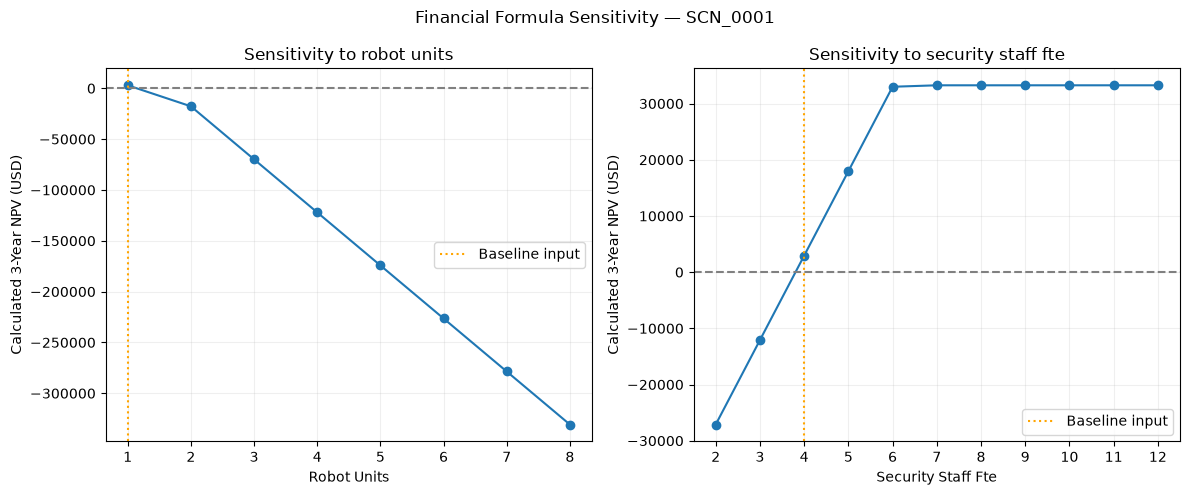

Saved results: outputs\W07_Sensitivity_Analysis.csv
Saved figure: outputs\W07_Sensitivity_Analysis.png


In [20]:
# Select a reproducible baseline from the training scenarios.
baseline_id = (
    training_data.sort_values("scenario_id")
    .iloc[SENSITIVITY_BASE_POSITION]["scenario_id"]
)

baseline = deployment_df.loc[
    deployment_df["scenario_id"] == baseline_id
].iloc[0].copy()

# Change one input at a time within the configured scenario range.
sensitivity_rows = []

for feature in SENSITIVITY_FEATURES:
    minimum, maximum = SCENARIO_RANGES[feature]

    for value in range(int(minimum), int(maximum) + 1):
        row = baseline.to_dict()
        row["scenario_id"] = f"SENS_{feature}_{value}"
        row["baseline_scenario_id"] = baseline_id
        row["sensitivity_feature"] = feature
        row["sensitivity_value"] = value
        row[feature] = value
        sensitivity_rows.append(row)

sensitivity_inputs = pd.DataFrame(sensitivity_rows)

# Recalculate NPV using the original financial assumptions.
sensitivity_df, _ = calculate_deployment_npv(
    sensitivity_inputs,
    FINANCIAL_ASSUMPTIONS,
    SUBSCRIPTION_TIERS,
    PROJECT_YEARS,
    DISCOUNT_RATE,
    DAYS_PER_YEAR,
    MONTHS_PER_YEAR,
)

result_columns = [
    "baseline_scenario_id",
    "sensitivity_feature",
    "sensitivity_value",
    "robot_units",
    "security_staff_fte",
    "annual_labor_savings_usd",
    "annual_operating_cost_usd",
    "initial_investment_usd",
    TARGET_COLUMN,
]

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
sensitivity_df[result_columns].to_csv(
    SENSITIVITY_RESULTS_PATH, index=False
)

print(f"Baseline training scenario: {baseline_id}")
display(
    baseline[
        FEATURE_COLUMNS + [TARGET_COLUMN]
    ].to_frame(name="baseline_value")
)
display(sensitivity_df[result_columns].round(2))

# Plot the one-at-a-time sensitivity results.
fig, axes = plt.subplots(
    1,
    len(SENSITIVITY_FEATURES),
    figsize=(6 * len(SENSITIVITY_FEATURES), 5),
    squeeze=False,
)

for ax, feature in zip(axes.ravel(), SENSITIVITY_FEATURES):
    subset = sensitivity_df.loc[
        sensitivity_df["sensitivity_feature"] == feature
    ].sort_values("sensitivity_value")

    ax.plot(
        subset["sensitivity_value"],
        subset[TARGET_COLUMN],
        marker="o",
    )
    ax.axhline(0, color="gray", linestyle="--")
    ax.axvline(
        baseline[feature],
        color="orange",
        linestyle=":",
        label="Baseline input",
    )
    ax.set(
        title=f"Sensitivity to {feature.replace('_', ' ')}",
        xlabel=feature.replace("_", " ").title(),
        ylabel=f"Calculated {PROJECT_YEARS}-Year NPV (USD)",
    )
    ax.set_xticks(subset["sensitivity_value"])
    ax.ticklabel_format(style="plain", axis="y")
    ax.grid(alpha=0.2)
    ax.legend()

fig.suptitle(f"Financial Formula Sensitivity — {baseline_id}")
fig.tight_layout()
fig.savefig(SENSITIVITY_PLOT_PATH, dpi=300, bbox_inches="tight")
plt.show()

print(f"Saved results: {SENSITIVITY_RESULTS_PATH}")
print(f"Saved figure: {SENSITIVITY_PLOT_PATH}")

### Sensitivity Analysis Findings

The baseline scenario, SCN_0001, includes one robot, four security
staff FTE, and a patrol area of 7.62 hectares. Its calculated
three-year NPV is $2,939.47.

Increasing the robot count reduces NPV in this scenario.
A second robot increases area coverage, but the additional savings
do not offset its acquisition and recurring costs. Two robots
provide full area coverage; additional units then increase costs
without increasing the calculated labor savings.

Increasing baseline security staff FTE raises potential labor
savings. However, the curve approaches a plateau around six to
seven FTE because the available operating capacity of one robot
limits further savings.

These findings explain why fleet size and baseline staffing are
important model inputs. The results apply to this baseline and
the specified financial assumptions, rather than all deployments.

Because the baseline NPV is close to zero relative to the model's
overall test RMSE, break-even decisions should use the direct
financial calculation rather than the ML prediction alone.